# 3. Refit the Senate models

This notebook reproduces the fitting procedure behind the Senate illustration. We will validate the bundled data, estimate both distance models at three prior scales, check the saved results, and interpret figures made from the new estimates.

**The default is a full run.** It uses the recorded starts, tolerances, and focused continuations. A recent run took about 80 seconds; runtime and numerical agreement depend on the software and machine. Optional `smoke` mode shortens optimization to check that the code runs and supplies no manuscript estimates.

Each Run All creates a new timestamped folder under `outputs/`. The reference results remain available for comparison. To repeat the fitting cell, rerun the configuration cell first. If you only need to inspect the saved manuscript results, use `1_reproduce_manuscript.ipynb`. See the README for environment setup.


In [1]:
from pathlib import Path
import json
import os
import sys

# Find the repository when Jupyter starts at its root or a directory below it.
working_directory = Path.cwd().resolve()
ROOT = next(
    (candidate for candidate in (working_directory, *working_directory.parents)
     if (candidate / "idealpoint").is_dir()
     and (candidate / "reference").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the replication repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA = ROOT / "data"
REFERENCE = ROOT / "reference"
os.environ.setdefault("MPLBACKEND", "Agg")
cache_directory = ROOT / "outputs" / "_matplotlib"
cache_directory.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(cache_directory))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

print("Repository:", ROOT.name)


Repository: public


## 1. What are we estimating?

For senator $i$ and roll call $j$, let $Y_{ij}=1$ denote Yea and $Y_{ij}=0$ denote Nay. Both models use two-dimensional coordinates $z_i,w_j$ and additive intercepts $a_i,b_j$:

$$
\Pr(Y_{ij}=1)=\operatorname{logit}^{-1}(\eta_{ij}),
\qquad \eta_{ij}=a_i+b_j-\|z_i-w_j\|_2^q,
\qquad q\in\{1,2\}.
$$

The distance coefficient is fixed at one. The intercepts have independent $N(0,3^2)$ priors; each coordinate has an independent $N(0,s^2)$ prior, with $s\in\{0.5,1,2\}$. For each pair $(q,s)$, we minimize the negative log posterior, up to an additive constant:

$$
L_{q,s}=\sum_{(i,j)\in\mathcal T}
\left[\log(1+\exp(\eta_{ij}))-Y_{ij}\eta_{ij}\right]
+\frac{\sum_i a_i^2+\sum_j b_j^2}{2\cdot3^2}
+\frac{\sum_i\|z_i\|_2^2+\sum_j\|w_j\|_2^2}{2s^2}.
$$

Here $\mathcal T$ contains training votes only. The held-out responses are used later for scoring. Equal coordinate priors across $q$ induce different priors on vote probabilities, so this is a comparison under the specified priors. It is an approximate joint MAP illustration, rather than a replication of the original papers' Bayesian procedures.

First, validate the bundled raw-file hashes and reconstruct the frozen split. This step does not fit a model or download data.


In [2]:
from idealpoint import fit

fit.configure_paths(data_dir=DATA)
design = fit.prepare_data()
data_summary = pd.DataFrame({
    "Quantity": ["Retained senators", "Retained roll calls", "Observed Yea/Nay votes",
                 "Training votes", "Held-out votes", "Missing retained-grid entries"],
    "Count": [design[key] for key in
              ("n_members", "n_rollcalls", "n_observed", "n_train", "n_test", "n_missing")],
})
display(data_summary.set_index("Quantity"))
print("Congress:", design["congress"], design["chamber"])
print("Dates:", design["date_min"], "to", design["date_max"])
print("Split seed:", design["split"]["seed"])
assert design["n_train"] + design["n_test"] == design["n_observed"]


,Count
Quantity,
Retained senators,96
Retained roll calls,373
Observed Yea/Nay votes,35182
Training votes,28164
Held-out votes,7018
Missing retained-grid entries,626


Congress: 114 Senate
Dates: 2015-01-08 to 2016-12-10
Split seed: 20261023


The data are the 114th Senate's roll calls from Voteview. Only cast codes 1 and 6 enter as Yea and Nay. Other responses are missing, rather than coded as Nay. Senators must participate in at least 80% of roll calls. Among retained senators, roll calls must have at least 80% participation, at least 50 training votes, and a training Yea share between 0.1 and 0.9.

A seeded 20% holdout is drawn on the sorted member-by-roll grid before outcome-based roll filtering. That filter uses training outcomes only. This entrywise split evaluates additional votes by senators and on roll calls represented in training; it does not evaluate a new Congress or entirely new senators or roll calls. Party labels and external ideal-point estimates do not enter the fitted objective.


## 2. Choose the execution mode

Leave the default `full` setting to reproduce the recorded fitting protocol. To make a quick software check, set `IDEALPOINT_MODE=smoke` before execution or change `MODE` in this cell. The mode is recorded with the results and shown with the figures.

The output name includes the current time so repeated runs can be compared without overwriting one another.


In [3]:
from datetime import datetime, timezone

MODE = os.environ.get("IDEALPOINT_MODE", "full").strip().lower()
# Optional quick check: MODE = "smoke"
if MODE not in {"full", "smoke"}:
    raise ValueError("IDEALPOINT_MODE must be 'full' or 'smoke'.")

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT = ROOT / "outputs" / f"{MODE}-refit-{run_stamp}"
print("Run mode:", MODE)
print("Output directory:", OUTPUT.relative_to(ROOT))
if MODE == "smoke":
    display(Markdown("**Smoke mode: the estimates below are software-test outputs, not manuscript estimates.**"))


Run mode: full
Output directory: outputs/full-refit-20261109T043933346582Z


## 3. Follow the fixed fitting protocol

At $s=1$, full mode uses eight shared starts for each exponent: a training-residual SVD, a perturbed SVD, and six seeded Gaussian starts. At each other scale, the starts are the selected $s=1$ fit and the same seeded Gaussian start. Each selected solution minimizes the training objective among the starts actually tried. All three scales are reported; held-out scores select neither starts nor scales.

L-BFGS-B uses the exact norm for $q=1$, with the zero vector selected as a subgradient at exact coincidence. The norm is not smoothed. Full mode also revisits a selected $q=1$ fit when its largest absolute gradient component exceeds 0.1, starting from that fit and a coordinate perturbation with standard deviation $10^{-4}$.

The seeds and one-thread linear algebra setting make the run reproducible within a compatible environment. Changes in numerical libraries or hardware can still change the optimization path.


In [4]:
protocol = pd.DataFrame({
    "Stage": ["Baseline fits at s=1", "Fits at s=0.5 and s=2", "Focused q=1 continuations"],
    "Starts per model": [8 if MODE == "full" else 1, 2,
                         "2 when the gradient threshold is exceeded" if MODE == "full" else "Skipped"],
    "Iteration limit": [2500 if MODE == "full" else 30,
                        2500 if MODE == "full" else 30,
                        10000 if MODE == "full" else 0],
})
display(protocol.set_index("Stage"))
print("Baseline seeds:", design["optimization_plan"]["seeds"])
print("Initial-fit tolerances:",
      "ftol =", design["optimization_plan"]["ftol"],
      "and gtol =", design["optimization_plan"]["gtol"])


,Starts per model,Iteration limit
Stage,,
Baseline fits at s=1,8,2500
Fits at s=0.5 and s=2,2,2500
Focused q=1 continuations,2 when the gradient threshold is exceeded,10000


Baseline seeds: [104729, 130363, 155921, 181081, 206369, 231779, 257053, 282407]
Initial-fit tolerances: ftol = 1e-11 and gtol = 1e-05


## 4. Estimate and save the results

The next cell runs the optimizations, reconstructs scores from the saved parameters, and renders the study figures. Detailed per-start output is captured in `optimization_log.txt`; the notebook presents selected results below. The recorded time includes fitting, checking, and rendering on this machine.


In [5]:
from contextlib import redirect_stdout
from io import StringIO
from time import perf_counter
from idealpoint.study import run

if OUTPUT.exists():
    raise FileExistsError("Rerun the configuration cell to create a fresh output folder.")
optimizer_log = StringIO()
started = perf_counter()
try:
    with redirect_stdout(optimizer_log):
        run_report = run(mode=MODE, output_dir=OUTPUT)
finally:
    if OUTPUT.exists():
        (OUTPUT / "optimization_log.txt").write_text(optimizer_log.getvalue(), encoding="utf-8")
elapsed_seconds = perf_counter() - started
print(f"Completed {MODE} run in {elapsed_seconds:.1f} seconds.")
print("Detailed optimization log:", (OUTPUT / "optimization_log.txt").relative_to(ROOT))
print("Selected model/scale fits:", sum(len(models) for models in run_report["sensitivity"].values()))


Matplotlib is building the font cache; this may take a moment.


Completed full run in 97.9 seconds.
Detailed optimization log: outputs/full-refit-20261109T043933346582Z/optimization_log.txt
Selected model/scale fits: 6


## 5. Read the predictive scores

Log loss is the mean negative log probability assigned to the observed response; Brier score is the mean squared error of the predicted Yea probability. Lower values indicate better prediction on the entries being scored. Training log loss omits the prior penalty and is therefore distinct from the optimization objective.

Compare the two exponents at each fixed $s$, then examine how the comparison changes with $s$. All three prespecified scales are shown; the held-out outcomes are used only after the starts have been selected by their training objectives.


In [6]:
score_rows = []
for s in (0.5, 1.0, 2.0):
    for q in (2, 1):
        selected = run_report["sensitivity"][str(s)][str(q)]
        score_rows.append({
            "s": s, "q": q,
            "Training log loss": selected["training"]["negative_log_likelihood"],
            "Held-out log loss": selected["held_out"]["negative_log_likelihood"],
            "Held-out Brier": selected["held_out"]["brier"],
        })
score_table = pd.DataFrame(score_rows)
display(score_table.set_index(["s", "q"]).style.format("{:.6f}"))
fresh_scores = pd.read_csv(OUTPUT / "fit_comparison_results_scores.csv")
assert len(score_table) == 6 and np.isfinite(score_table.to_numpy()).all()


## 6. Check what was reproduced

The independent checks rebuild the split from raw records and reconstruct logits, objectives, scores, and descriptive geometry from the saved parameter vectors. Passing these checks means the files and calculations agree. It does not certify an optimizer's stationarity or global optimality.

In full mode, the reference archive is checked as well. Agreement between fresh and reference estimates is reported separately from internal consistency.


In [7]:
from idealpoint.checks import verify_results

verification = verify_results(OUTPUT, DATA, compare_reference=(MODE == "full"))
check_rows = [
    {"Check": "All internal checks", "Passed": verification["passed"]},
    {"Check": "Exact arithmetic checks", "Passed": verification["checks"]["exact_arithmetic"]},
]
comparison = verification["reference_comparison"]
if comparison["performed"]:
    check_rows.append({"Check": "Reference archive consistency",
                       "Passed": comparison["reference_internal_consistency_passed"]})
display(pd.DataFrame(check_rows).set_index("Check"))
failed_checks = [name for name, passed in verification["checks"].items() if not passed]
print(f"Passed {len(verification['checks']) - len(failed_checks)} of {len(verification['checks'])} checks.")
assert verification["passed"], f"Failed consistency checks: {failed_checks}"
print("Full verification report:", (OUTPUT / "fit_verification.json").relative_to(ROOT))


,Passed
Check,
All internal checks,True
Exact arithmetic checks,True
Reference archive consistency,True


Passed 54 of 54 checks.
Full verification report: outputs/full-refit-20261109T043933346582Z/fit_verification.json


For a full run, the next table compares held-out scores against the reference at the same $(s,q)$. Differences are fresh minus reference. Small discrepancies can arise from numerical optimization; larger ones should be examined alongside training objectives and stopping diagnostics. Smoke mode skips this comparison.


In [8]:
if MODE == "full":
    reference_scores = pd.read_csv(REFERENCE / "fit_comparison_results_scores.csv")
    comparisons = fresh_scores.merge(
        reference_scores, on=["coordinate_sd", "q"],
        suffixes=("_fresh", "_reference"), validate="one_to_one",
    )
    comparison_table = pd.DataFrame({
        "s": comparisons["coordinate_sd"], "q": comparisons["q"],
        "Fresh log loss": comparisons["negative_log_likelihood_fresh"],
        "Reference log loss": comparisons["negative_log_likelihood_reference"],
        "Log-loss difference": comparisons["negative_log_likelihood_fresh"]
                               - comparisons["negative_log_likelihood_reference"],
        "Brier difference": comparisons["brier_fresh"] - comparisons["brier_reference"],
    })
    display(comparison_table.set_index(["s", "q"]).style.format({
        "Fresh log loss": "{:.6f}", "Reference log loss": "{:.6f}",
        "Log-loss difference": "{:.3e}", "Brier difference": "{:.3e}",
    }))
else:
    print("Reference comparison skipped: smoke mode uses a shorter fitting protocol.")


## 7. Examine the optimization diagnostics

Read the solver's success flag together with the gradient and stopping message. A relative-objective stopping criterion can be satisfied while some gradient components remain large. Near-coincident points make this especially important for the nonsmooth $q=1$ objective.

The first table summarizes the selected fit at each scale. When focused continuations were run, the second table records their changes. A negative objective change is an improvement in the penalized training criterion; a small change in predictions shows numerical stability under those continuations, rather than establishing stationarity.


In [9]:
diagnostic_rows = []
for s in (0.5, 1.0, 2.0):
    for q in (2, 1):
        selected = run_report["sensitivity"][str(s)][str(q)]["selected_start"]
        diagnostic_rows.append({
            "s": s, "q": q, "Selected start": str(selected["start_id"]),
            "Iterations": selected["iterations"],
            "Largest absolute gradient": selected["max_abs_gradient"],
            "Solver success flag": selected["success"],
        })
display(pd.DataFrame(diagnostic_rows).set_index(["s", "q"]).style.format({
    "Largest absolute gradient": "{:.3e}",
}))

refinements = run_report.get("focused_refinements", [])
if refinements:
    display(Markdown("**Changes after focused q=1 continuations**"))
    refinement_table = pd.DataFrame([{
        "s": item["coordinate_sd"],
        "Objective change": item["objective_change"],
        "Held-out log-loss change": item["held_out_log_loss_change"],
        "Mean absolute probability change": item["held_out_probability_mean_abs_change"],
        "Largest absolute probability change": item["held_out_probability_max_abs_change"],
    } for item in refinements])
    display(refinement_table.set_index("s").style.format("{:.3e}"))
else:
    print("No focused continuations were run.")
print("Full stopping messages: fit_comparison_results.json; per-start progress: optimization_log.txt.")


**Changes after focused q=1 continuations**

,Objective change,Held-out log-loss change,Mean absolute probability change,Largest absolute probability change
s,,,,
0.500000,-1.933e-02,-8.779e-06,5.847e-05,1.097e-03
1.000000,-3.043e-04,1.316e-07,3.113e-06,5.006e-05


Full stopping messages: fit_comparison_results.json; per-start progress: optimization_log.txt.


### How much did the baseline starts differ?

Each panel below subtracts the smallest objective among the initial $s=1$ starts for that exponent. A point at zero marks the best initial start. Compare starts **within a panel**: the panels have separate vertical scales, and raw objectives across $q$ are not used as model-comparison scores.

These are the initial-start outcomes, before any focused continuation. A narrow spread shows agreement among the tried starts; it does not rule out an unvisited better solution. Smoke mode has only one initial start per exponent, so its zero gaps contain no information about sensitivity to initialization.


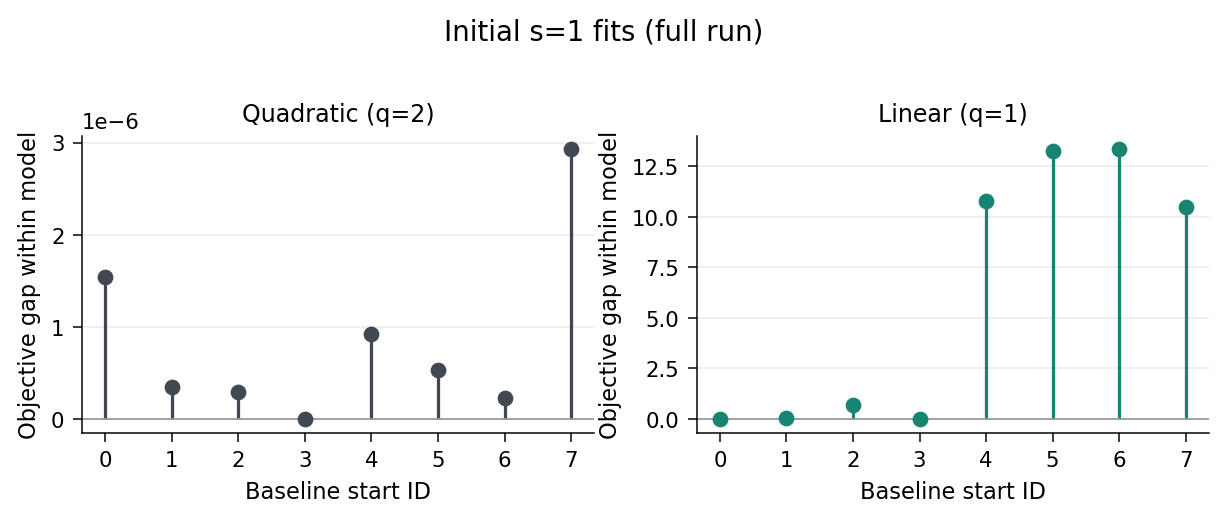

In [10]:
import matplotlib.pyplot as plt

starts = pd.DataFrame(run_report["all_starts"])
is_initial = starts["start_id"].map(lambda value: isinstance(value, (int, np.integer)))
baseline_starts = starts.loc[starts["coordinate_sd"].eq(1.0) & is_initial].copy()
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8), sharey=False)
for ax, q, title, color in zip(
    axes, (2, 1), ("Quadratic (q=2)", "Linear (q=1)"), ("#424851", "#178571")
):
    group = baseline_starts.loc[baseline_starts["q"].eq(q)].sort_values("start_id")
    start_ids = group["start_id"].astype(int).to_numpy()
    gaps = group["objective"].to_numpy() - group["objective"].min()
    ax.vlines(start_ids, 0, gaps, color=color, linewidth=1.3)
    ax.scatter(start_ids, gaps, color=color, s=28, zorder=3)
    ax.axhline(0, color="#999999", linewidth=0.7)
    ax.set(title=title, xlabel="Baseline start ID", ylabel="Objective gap within model")
    ax.set_xticks(start_ids)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useOffset=False)
    ax.grid(axis="y", color="#e9ebee", linewidth=0.6)
    ax.set_axisbelow(True)
fig.suptitle(f"Initial s=1 fits ({MODE} run)", y=1.02, fontsize=11)
fig.tight_layout()
start_figure = OUTPUT / "figures" / "baseline_start_gaps.png"
fig.savefig(start_figure, dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(start_figure), width=760))


## 8. Read the fresh Senate illustration

Panels A and B show the selected $s=1$ maps. Senators and roll calls receive a common orthogonal rotation within each model, preserving distances and the isotropic coordinate prior. Both panels use the same coordinate scales. Party labels help orient and describe the maps; they are not used to estimate the positions.

Panel C shows held-out log loss for every prior scale. The coordinates and losses below come from this run, not from the reference archive.


**Fresh Senate illustration — full run**

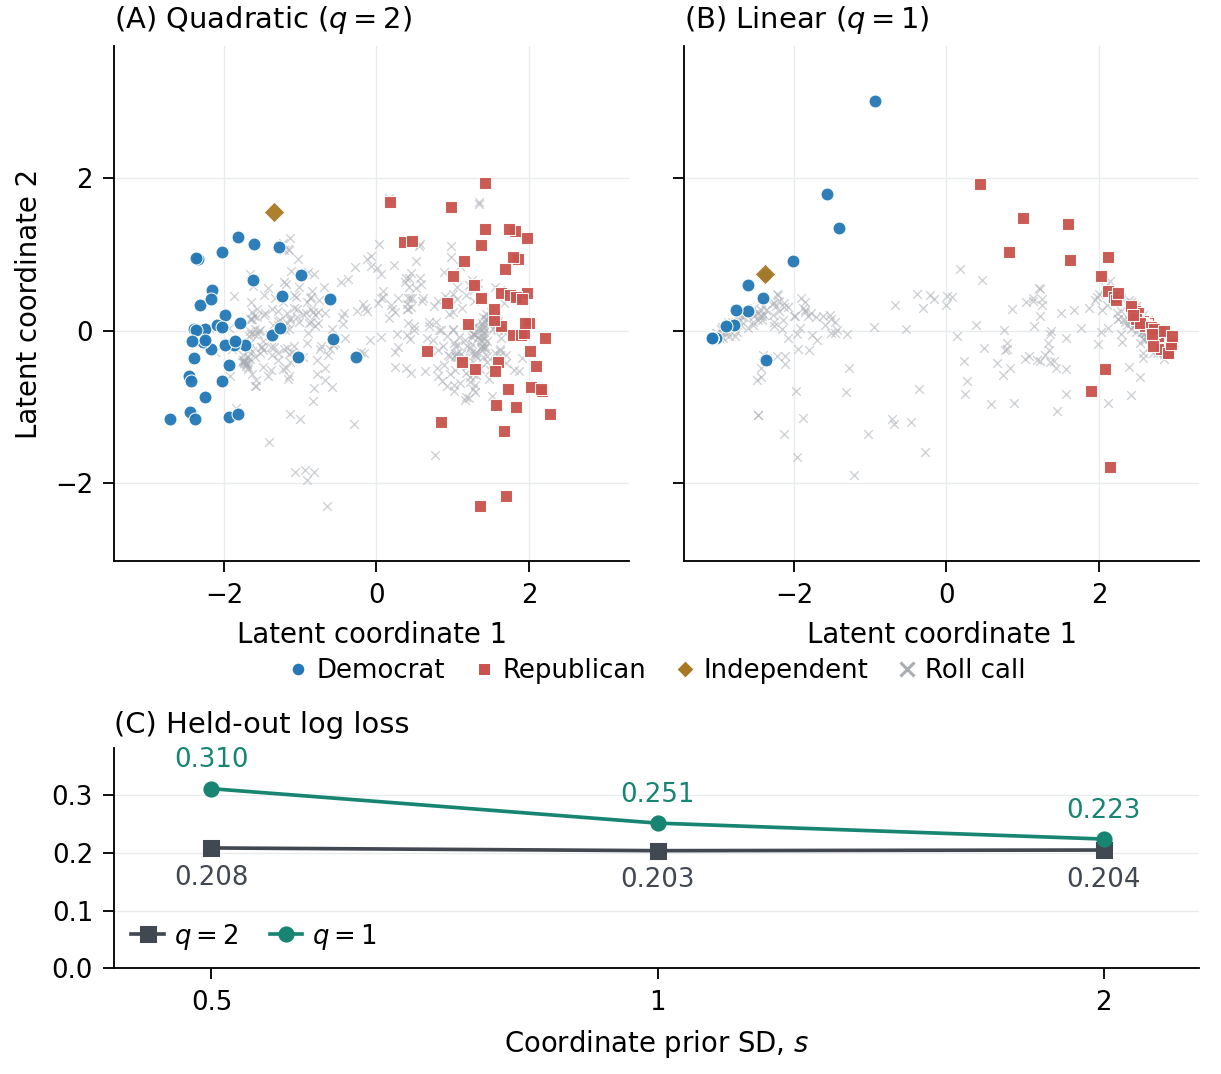

In [11]:
main_figure = OUTPUT / "figures" / "senate_illustration.png"
if not main_figure.is_file():
    raise FileNotFoundError("The fresh Senate figure was not generated.")
display(Markdown(f"**Fresh Senate illustration — {MODE} run**"))
display(Image(filename=str(main_figure), width=760))


Look first at party separation and within-party concentration, then compare those visual patterns with panel C. A compact party cluster need not imply better vote prediction. These are descriptive summaries of known parties, not tests of recovery of unknown factions.

Overlapping symbols can represent several senators at nearly the same fitted position. For either exponent, the coordinate scale is set by the model and priors; interpreting an axis or a distance ratio politically requires additional substantive evidence. These are point estimates without posterior uncertainty intervals.


### Compare the second predictive criterion

The supplementary figure uses the same fitted positions and adds held-out Brier scores. Read the log-loss and Brier panels together: they summarize different aspects of probability error on the same held-out entries. Their agreement, if present, is evidence for this particular comparison and does not remove the prior or optimization qualifications.


**Fresh supplementary comparison — full run**

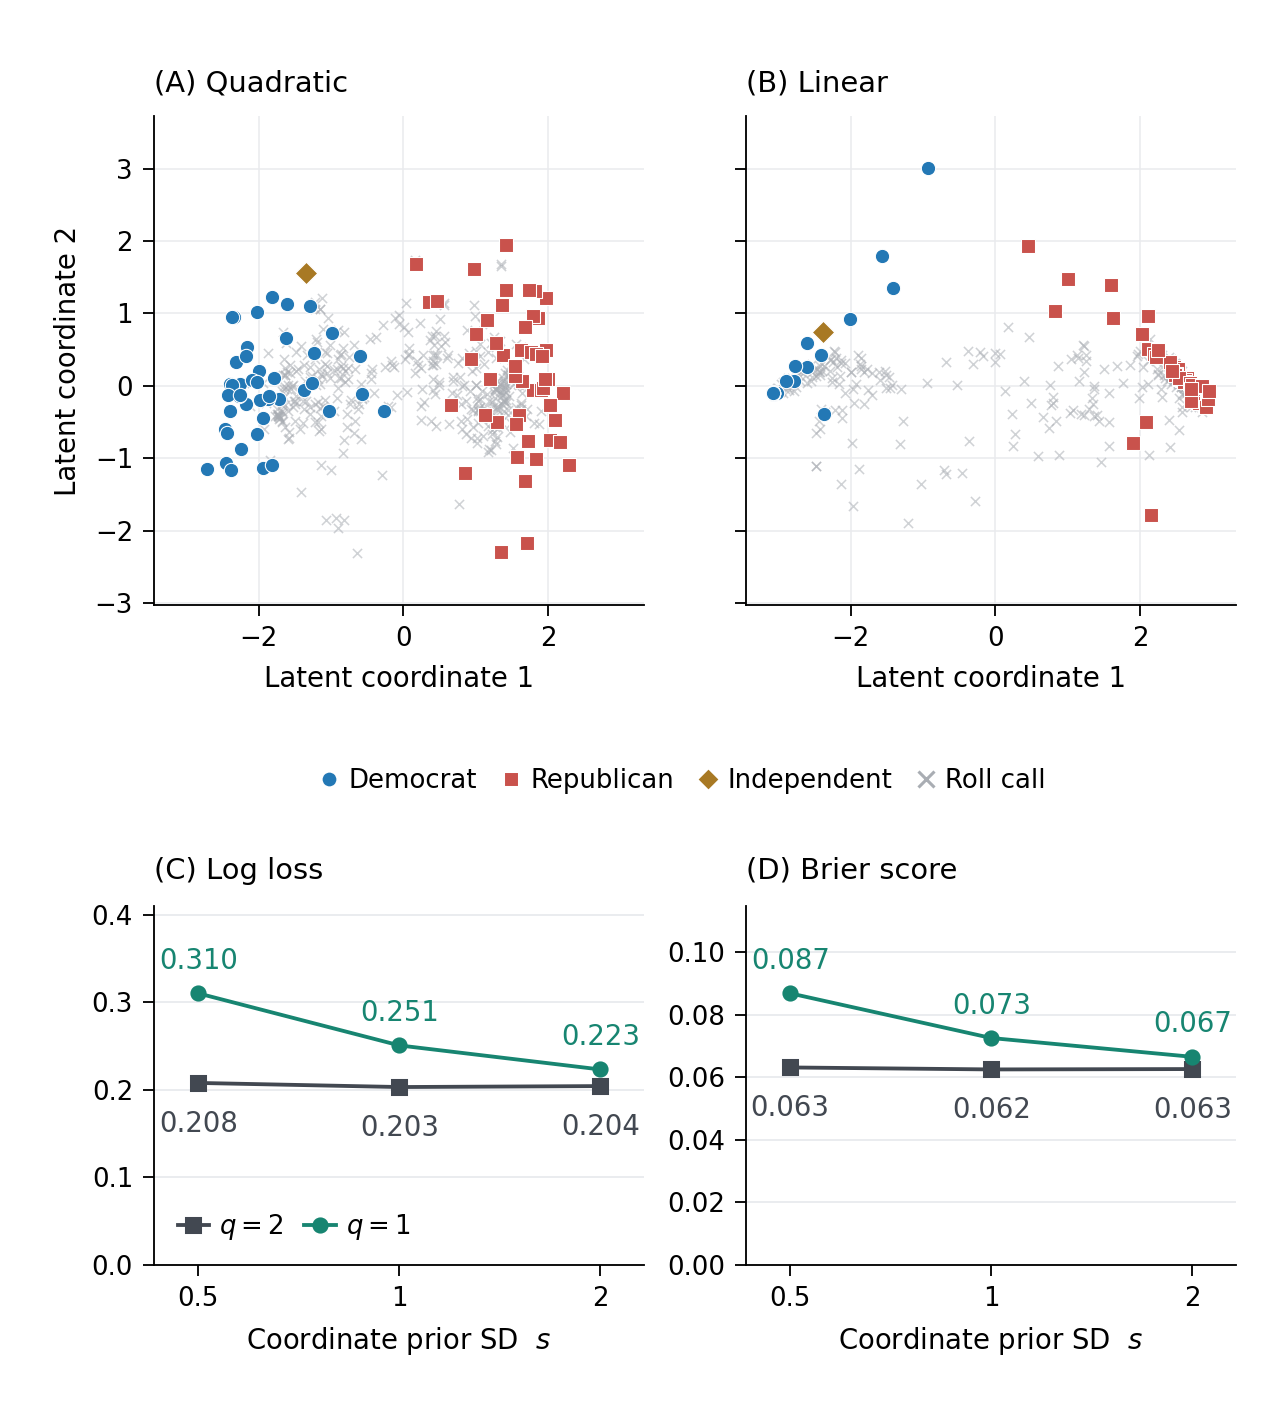

In [12]:
supplementary_figure = OUTPUT / "figures" / "fit_comparison.png"
if not supplementary_figure.is_file():
    raise FileNotFoundError("The fresh supplementary figure was not generated.")
display(Markdown(f"**Fresh supplementary comparison — {MODE} run**"))
display(Image(filename=str(supplementary_figure), width=760))


## 9. What this rerun establishes

A successful full execution reproduces the stated preprocessing and estimation procedure and reports how closely its outputs agree with the archived run. The predictive comparison is conditional on one Congress, one entrywise split, the specified priors, and finite-start local optimization. It cannot establish general superiority of either model family.

The empirical maps illustrate consequences of the response specification and fitting choices. The letter's mathematical distinction between a Euclidean distance and its transformation in a response model is a separate result.

The main numerical records and figures are saved below. The notebook's displayed PNG images are embedded when its executed state is saved, so they remain visible when the notebook is reopened.


In [13]:
artifacts = {
    "Selected parameters and logits": OUTPUT / "fit_comparison_results.npz",
    "Scores": OUTPUT / "fit_comparison_results_scores.csv",
    "All starts and stopping diagnostics": OUTPUT / "fit_comparison_results.json",
    "Detailed optimizer log": OUTPUT / "optimization_log.txt",
    "Independent verification": OUTPUT / "fit_verification.json",
    "Senate figure (PDF)": OUTPUT / "figures" / "senate_illustration.pdf",
    "Supplementary figure (PDF)": OUTPUT / "figures" / "fit_comparison.pdf",
    "Baseline-start diagnostic": start_figure,
}
assert all(path.is_file() for path in artifacts.values()), "A run artifact is missing."
display(pd.DataFrame({
    "Artifact": list(artifacts),
    "Path relative to this run": [str(path.relative_to(OUTPUT)) for path in artifacts.values()],
}).set_index("Artifact"))


,Path relative to this run
Artifact,
Selected parameters and logits,fit_comparison_results.npz
Scores,fit_comparison_results_scores.csv
All starts and stopping diagnostics,fit_comparison_results.json
Detailed optimizer log,optimization_log.txt
Independent verification,fit_verification.json
Senate figure (PDF),figures/senate_illustration.pdf
Supplementary figure (PDF),figures/fit_comparison.pdf
Baseline-start diagnostic,figures/baseline_start_gaps.png
